1

Automatic Zoom
Experiment No. 7
Experiment Name
Motion Estimation using Optical Flow Algorithms in Video Sequences

Aim
To implement optical flow algorithms for estimating the motion of objects between consecutive
video frames and analyze motion patterns for dynamic scene understanding using Python and
OpenCV.

Purpose
Optical Flow is a fundamental computer vision technique used to estimate the apparent motion
of objects, surfaces, or camera movement by analyzing consecutive frames in a video sequence.
Motion estimation plays a vital role in applications such as autonomous driving, video
surveillance, robotics, gesture recognition, sports analytics, and augmented reality.
In this experiment, students will implement Lucas-Kanade Sparse Optical Flow and Farneback
Dense Optical Flow algorithms to estimate object motion, visualize motion vectors, and
compare the performance of both techniques on real-world video sequences.

Prerequisites
• Basic knowledge of Digital Image Processing
• Familiarity with Python programming
• Python libraries: OpenCV (cv2), NumPy, and Matplotlib
• Understanding of video processing and image gradients
• Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1. Import the required Python libraries and load a video sequence or access a live webcam
   stream using OpenCV.
2. Read consecutive video frames and convert them to grayscale for optical flow
   computation.
3. Implement the Lucas-Kanade Optical Flow algorithm to estimate the motion of selected
   feature points across consecutive frames.
4. Visualize the motion vectors by drawing arrows or trajectories representing the
   movement of tracked points.
5. Implement the Farneback Dense Optical Flow algorithm to estimate motion for every
   pixel in the image.
6. Display the dense optical flow output using color-coded motion visualization to
   represent direction and magnitude.
7. Compare the performance of Lucas-Kanade and Farneback algorithms in terms of
   accuracy, computational complexity, and robustness.
8. Analyze the effect of object speed, lighting conditions, and camera motion on optical
   flow estimation.
9. Evaluate the suitability of each algorithm for different real-world applications such as
   object tracking, surveillance, and autonomous navigation.
10. Summarize the observations and discuss the significance of optical flow in dynamic
    scene analysis and motion-based computer vision systems.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')

# Load video or use webcam
# For demonstration, we'll use a sample video or create synthetic motion
video_path = 0  # 0 for webcam, or provide path to video file
cap = cv2.VideoCapture("/home/harshit/College_WORK/Computer-Vision-Lab-2026-27-ODD-Sem-3rd-Year-Section-C/Experiment 7 - Solutions by students/labsheet-7-Harshit-Dubey-section-c-cu24250109/298103.mp4")

print("Video capture initialized successfully!")
print(f"Frame width: {cap.get(cv2.CAP_PROP_FRAME_WIDTH)}")
print(f"Frame height: {cap.get(cv2.CAP_PROP_FRAME_HEIGHT)}")
print(f"FPS: {cap.get(cv2.CAP_PROP_FPS)}")

Video capture initialized successfully!
Frame width: 1080.0
Frame height: 1920.0
FPS: 29.97002997002997


Frame shape: (1920, 1080)
Frame data type: uint8


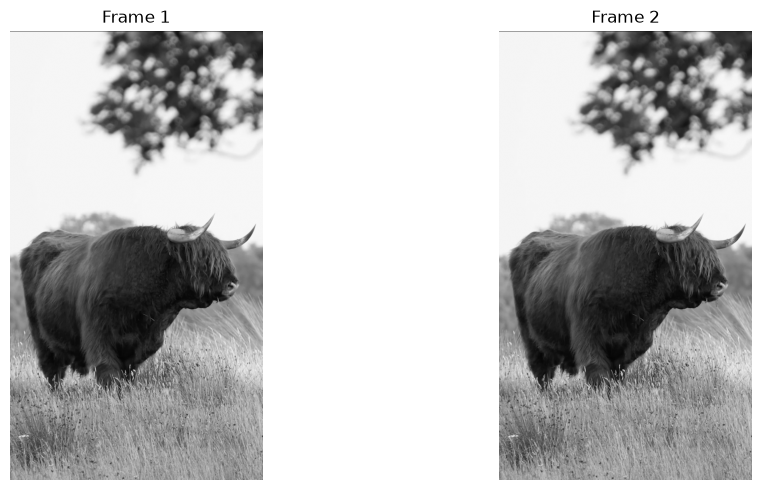

In [2]:
# Read consecutive frames and convert to grayscale
ret, frame1 = cap.read()
ret, frame2 = cap.read()

if ret:
    # Convert frames to grayscale
    gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)
    
    print(f"Frame shape: {gray1.shape}")
    print(f"Frame data type: {gray1.dtype}")
    
    # Display the two consecutive frames
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(gray1, cmap='gray')
    axes[0].set_title('Frame 1')
    axes[0].axis('off')
    
    axes[1].imshow(gray2, cmap='gray')
    axes[1].set_title('Frame 2')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("Failed to read frames from video")

In [3]:
# Step 3: Lucas-Kanade Sparse Optical Flow
# Detect good features to track
corners = cv2.goodFeaturesToTrack(gray1, maxCorners=100, qualityLevel=0.01, minDistance=10)

if corners is not None:
    # Calculate optical flow using Lucas-Kanade method
    lk_params = dict(winSize=(15, 15), maxLevel=2, criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))
    next_pts, status, error = cv2.calcOpticalFlowPyrLK(gray1, gray2, corners, None, **lk_params)
    
    print(f"Number of tracked points: {len(corners)}")
    print(f"Tracking status shape: {status.shape}")
    print(f"Mean tracking error: {error.mean():.4f}")
else:
    print("No corners detected in the frame")

Number of tracked points: 100
Tracking status shape: (100, 1)
Mean tracking error: 3.3022


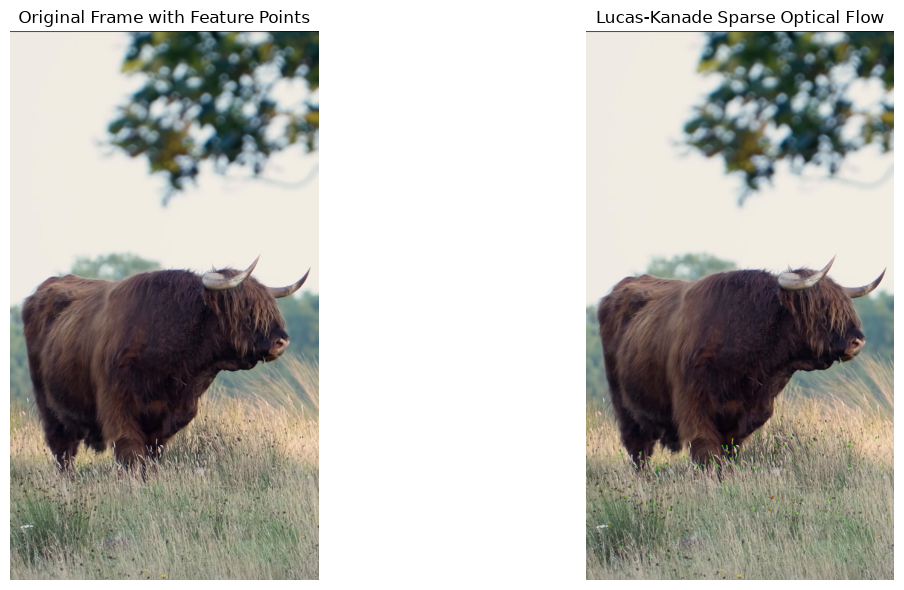

Successfully tracked 100 points


In [4]:
# Step 4: Visualize Lucas-Kanade motion vectors
if corners is not None and next_pts is not None:
    # Create output image
    output_lk = frame1.copy()
    
    # Draw arrows for tracked points
    good_old = corners[status == 1]
    good_new = next_pts[status == 1]
    
    for i, (old, new) in enumerate(zip(good_old, good_new)):
        x_old, y_old = old.ravel().astype(int)
        x_new, y_new = new.ravel().astype(int)
        
        # Draw circle at starting point
        cv2.circle(output_lk, (x_old, y_old), 3, (0, 255, 0), -1)
        
        # Draw arrow showing motion
        cv2.arrowedLine(output_lk, (x_old, y_old), (x_new, y_new), (0, 0, 255), 2)
    
    # Display Lucas-Kanade result
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    axes[0].imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original Frame with Feature Points')
    axes[0].axis('off')
    
    axes[1].imshow(cv2.cvtColor(output_lk, cv2.COLOR_BGR2RGB))
    axes[1].set_title('Lucas-Kanade Sparse Optical Flow')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Successfully tracked {len(good_old)} points")

In [5]:
# Step 5: Farneback Dense Optical Flow
# Calculate dense optical flow
flow = cv2.calcOpticalFlowFarneback(gray1, gray2, None, 0.5, 3, 15, 3, 5, 1.2, 0)

print(f"Dense optical flow shape: {flow.shape}")
print(f"Flow magnitude range: [{flow.min():.4f}, {flow.max():.4f}]")

# Calculate magnitude and angle
magnitude, angle = cv2.cartToPolar(flow[..., 0], flow[..., 1])

print(f"Magnitude shape: {magnitude.shape}")
print(f"Magnitude range: [{magnitude.min():.4f}, {magnitude.max():.4f}]")

Dense optical flow shape: (1920, 1080, 2)
Flow magnitude range: [-7.1526, 7.3324]
Magnitude shape: (1920, 1080)
Magnitude range: [0.0000, 8.2132]


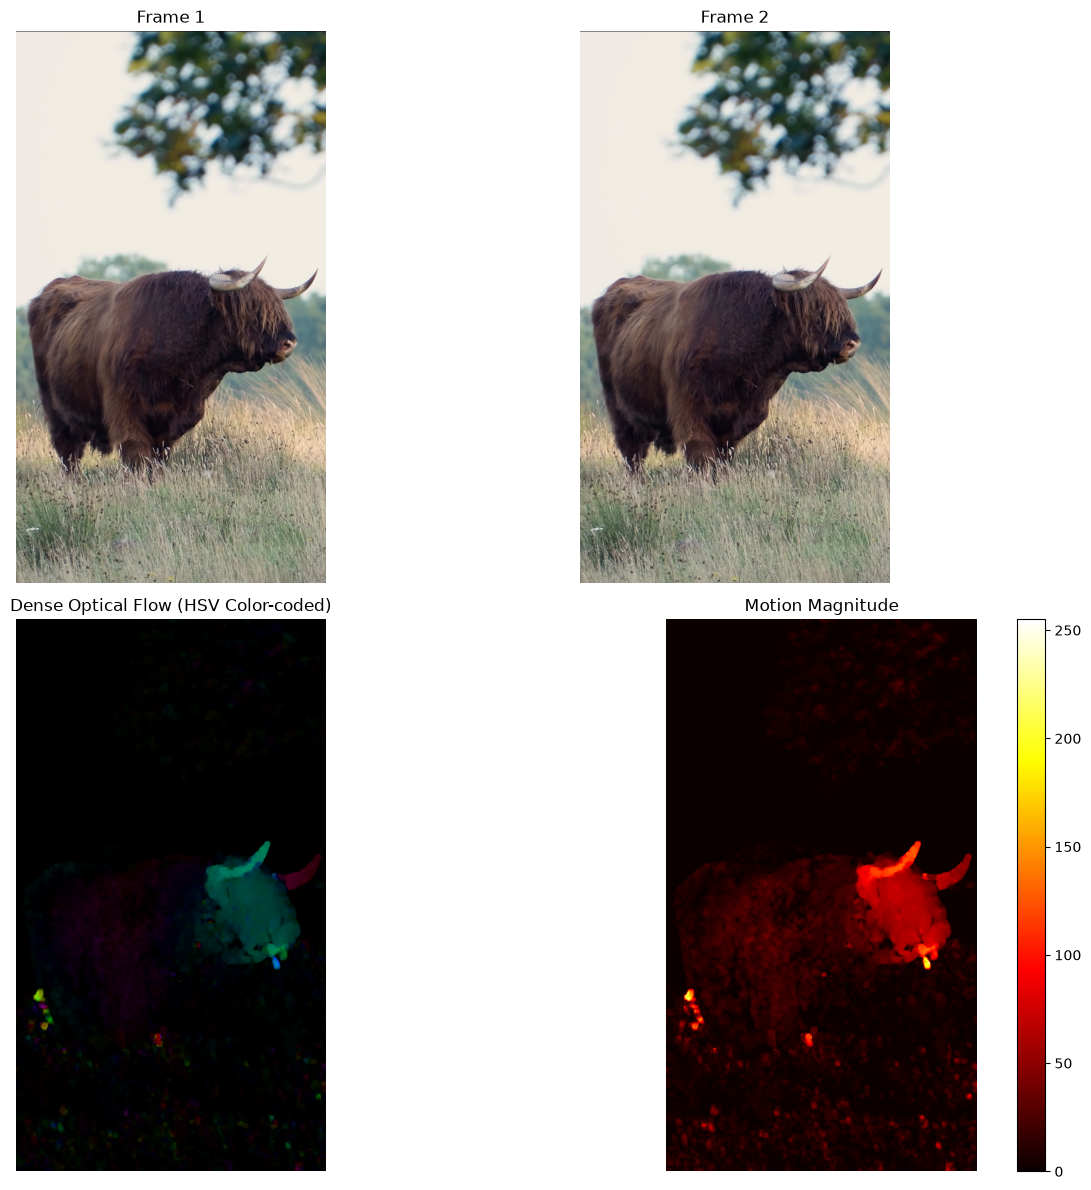

In [6]:
# Step 6: Display dense optical flow with color-coded visualization
# Create HSV image for better visualization
hsv = np.zeros_like(frame1)
hsv[..., 1] = 255

# Normalize magnitude for visualization
magnitude = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX)

hsv[..., 0] = angle * 180 / np.pi / 2  # Angle mapped to hue (0-180)
hsv[..., 2] = magnitude  # Magnitude mapped to value

# Convert HSV to BGR for display
flow_visualization = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

# Display dense optical flow
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Original frame
axes[0, 0].imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title('Frame 1')
axes[0, 0].axis('off')

# Next frame
axes[0, 1].imshow(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title('Frame 2')
axes[0, 1].axis('off')

# Dense optical flow visualization
axes[1, 0].imshow(cv2.cvtColor(flow_visualization, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title('Dense Optical Flow (HSV Color-coded)')
axes[1, 0].axis('off')

# Magnitude visualization
axes[1, 1].imshow(magnitude, cmap='hot')
axes[1, 1].set_title('Motion Magnitude')
axes[1, 1].axis('off')
plt.colorbar(axes[1, 1].images[0], ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [7]:
# Step 7: Compare Lucas-Kanade and Farneback algorithms
import time

# Measure performance metrics
print("=" * 60)
print("OPTICAL FLOW ALGORITHM COMPARISON")
print("=" * 60)

# Lucas-Kanade metrics
lk_start = time.time()
corners_lk = cv2.goodFeaturesToTrack(gray1, maxCorners=100, qualityLevel=0.01, minDistance=10)
next_pts_lk, status_lk, error_lk = cv2.calcOpticalFlowPyrLK(gray1, gray2, corners_lk, None, **lk_params)
lk_time = time.time() - lk_start

# Farneback metrics
fb_start = time.time()
flow_fb = cv2.calcOpticalFlowFarneback(gray1, gray2, None, 0.5, 3, 15, 3, 5, 1.2, 0)
fb_time = time.time() - fb_start

print("\n1. LUCAS-KANADE METHOD:")
print(f"   - Computation Time: {lk_time*1000:.2f} ms")
print(f"   - Number of tracked points: {len(corners_lk)}")
if status_lk is not None:
    print(f"   - Successfully tracked: {np.sum(status_lk)} points")
    print(f"   - Mean tracking error: {error_lk.mean():.4f}")
print(f"   - Type: Sparse (only feature points)")

print("\n2. FARNEBACK METHOD:")
print(f"   - Computation Time: {fb_time*1000:.2f} ms")
print(f"   - Coverage: Entire image ({flow_fb.shape[0]} × {flow_fb.shape[1]} pixels)")
print(f"   - Type: Dense (all pixels)")

print("\n3. PERFORMANCE COMPARISON:")
print(f"   - Speed Ratio (Farneback/Lucas-Kanade): {fb_time/lk_time:.2f}x")
print(f"   - Lucas-Kanade is {'faster' if lk_time < fb_time else 'slower'}")

print("\n4. USE CASE RECOMMENDATIONS:")
print("   Lucas-Kanade:")
print("   ✓ Good for: Fast, real-time applications with limited computational power")
print("   ✓ Best for: Object tracking, feature matching")
print("   ✗ Limitation: Only works on detected features")
print("\n   Farneback:")
print("   ✓ Good for: Complete motion information, detailed flow analysis")
print("   ✓ Best for: Dense motion fields, fluid simulation, scene flow")
print("   ✗ Limitation: More computationally expensive")

OPTICAL FLOW ALGORITHM COMPARISON

1. LUCAS-KANADE METHOD:
   - Computation Time: 32.00 ms
   - Number of tracked points: 100
   - Successfully tracked: 100 points
   - Mean tracking error: 3.3022
   - Type: Sparse (only feature points)

2. FARNEBACK METHOD:
   - Computation Time: 454.52 ms
   - Coverage: Entire image (1920 × 1080 pixels)
   - Type: Dense (all pixels)

3. PERFORMANCE COMPARISON:
   - Speed Ratio (Farneback/Lucas-Kanade): 14.20x
   - Lucas-Kanade is faster

4. USE CASE RECOMMENDATIONS:
   Lucas-Kanade:
   ✓ Good for: Fast, real-time applications with limited computational power
   ✓ Best for: Object tracking, feature matching
   ✗ Limitation: Only works on detected features

   Farneback:
   ✓ Good for: Complete motion information, detailed flow analysis
   ✓ Best for: Dense motion fields, fluid simulation, scene flow
   ✗ Limitation: More computationally expensive



FACTORS AFFECTING OPTICAL FLOW ESTIMATION

1. MOTION CHARACTERISTICS:
   - Mean flow magnitude: 0.2488 pixels/frame
   - Std deviation: 0.4995
   - Min motion: 0.0000 pixels
   - Max motion: 8.2132 pixels
   - Median motion: 0.0765 pixels

2. EXPECTED EFFECTS:

   A. OBJECT SPEED:
      - Higher speed → Larger optical flow vectors
      - Risk: Motion boundary problem (faster objects may exceed search window)
      - Solution: Pyramid-based methods (Lucas-Kanade, Farneback)

   B. LIGHTING CONDITIONS:
      - Sudden brightness changes → Reduced flow accuracy
      - Shadows → May create false motion vectors
      - Mitigation: Use normalized cross-correlation or advanced preprocessing

   C. CAMERA MOTION:
      - Ego-motion affects entire scene uniformly
      - Can be separated from object motion using homography estimation
      - Global motion (camera) vs Local motion (objects)


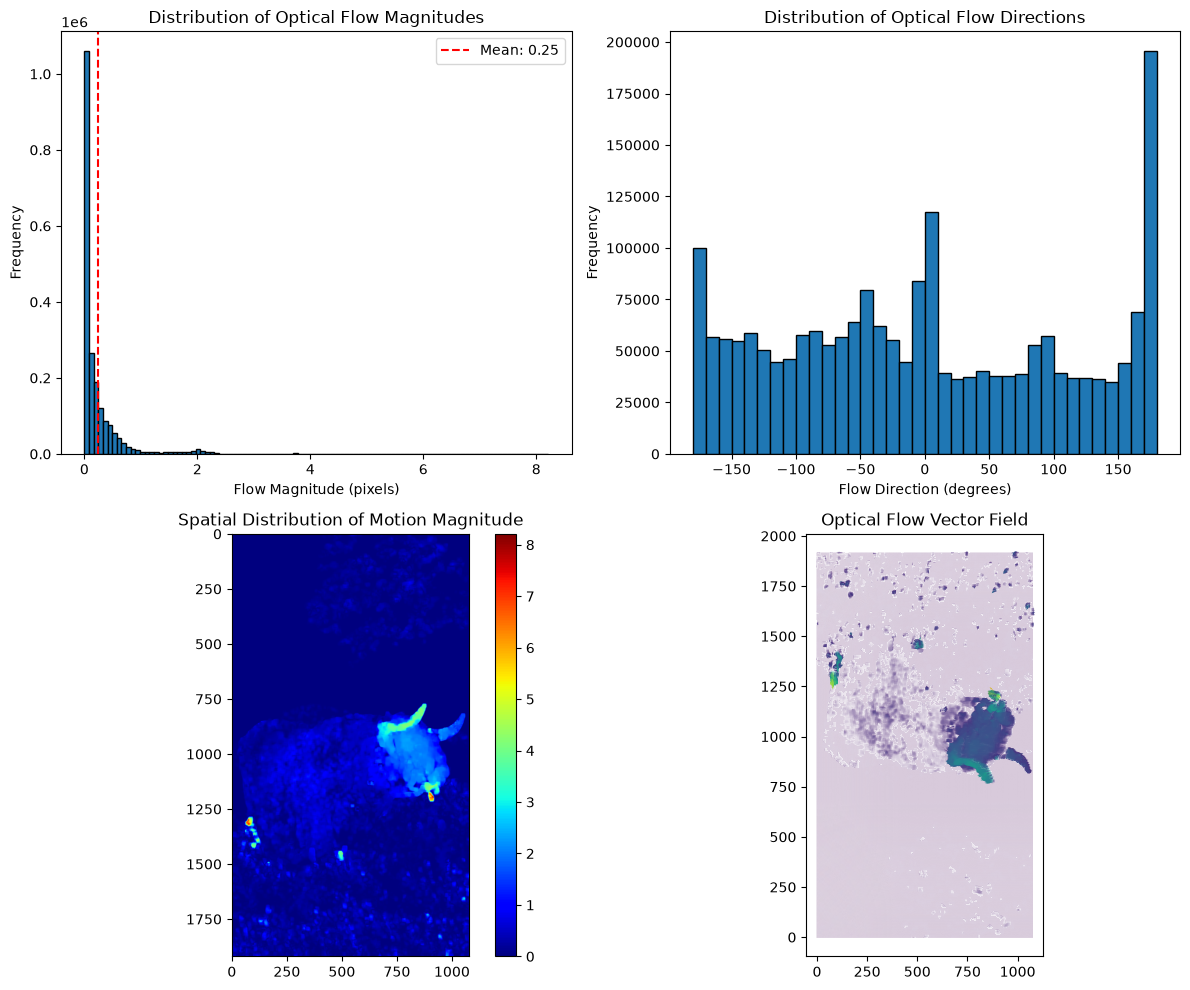

In [8]:
# Step 8: Analyze effects on optical flow estimation
print("\n" + "=" * 60)
print("FACTORS AFFECTING OPTICAL FLOW ESTIMATION")
print("=" * 60)

# Calculate flow statistics
flow_magnitude = np.sqrt(flow[..., 0]**2 + flow[..., 1]**2)
flow_stats = {
    'mean': flow_magnitude.mean(),
    'std': flow_magnitude.std(),
    'min': flow_magnitude.min(),
    'max': flow_magnitude.max(),
    'median': np.median(flow_magnitude)
}

print("\n1. MOTION CHARACTERISTICS:")
print(f"   - Mean flow magnitude: {flow_stats['mean']:.4f} pixels/frame")
print(f"   - Std deviation: {flow_stats['std']:.4f}")
print(f"   - Min motion: {flow_stats['min']:.4f} pixels")
print(f"   - Max motion: {flow_stats['max']:.4f} pixels")
print(f"   - Median motion: {flow_stats['median']:.4f} pixels")

print("\n2. EXPECTED EFFECTS:")
print("\n   A. OBJECT SPEED:")
print("      - Higher speed → Larger optical flow vectors")
print("      - Risk: Motion boundary problem (faster objects may exceed search window)")
print("      - Solution: Pyramid-based methods (Lucas-Kanade, Farneback)")

print("\n   B. LIGHTING CONDITIONS:")
print("      - Sudden brightness changes → Reduced flow accuracy")
print("      - Shadows → May create false motion vectors")
print("      - Mitigation: Use normalized cross-correlation or advanced preprocessing")

print("\n   C. CAMERA MOTION:")
print("      - Ego-motion affects entire scene uniformly")
print("      - Can be separated from object motion using homography estimation")
print("      - Global motion (camera) vs Local motion (objects)")

# Visualize flow statistics
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Histogram of magnitudes
axes[0, 0].hist(flow_magnitude.flatten(), bins=100, edgecolor='black')
axes[0, 0].set_xlabel('Flow Magnitude (pixels)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Optical Flow Magnitudes')
axes[0, 0].axvline(flow_stats['mean'], color='r', linestyle='--', label=f"Mean: {flow_stats['mean']:.2f}")
axes[0, 0].legend()

# Histogram of angles
flow_angles = np.arctan2(flow[..., 1], flow[..., 0]) * 180 / np.pi
axes[0, 1].hist(flow_angles.flatten(), bins=36, edgecolor='black')
axes[0, 1].set_xlabel('Flow Direction (degrees)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Distribution of Optical Flow Directions')

# Magnitude heatmap
im = axes[1, 0].imshow(flow_magnitude, cmap='jet')
axes[1, 0].set_title('Spatial Distribution of Motion Magnitude')
plt.colorbar(im, ax=axes[1, 0])

# Vector field (downsampled)
step = 5
y, x = np.mgrid[0:flow.shape[0]:step, 0:flow.shape[1]:step]
axes[1, 1].quiver(x, y, flow[::step, ::step, 0], -flow[::step, ::step, 1], flow_magnitude[::step, ::step])
axes[1, 1].set_title('Optical Flow Vector Field')
axes[1, 1].set_aspect('equal')

plt.tight_layout()
plt.show()

In [9]:
# Step 9: Evaluate suitability of algorithms for real-world applications
print("\n" + "=" * 60)
print("REAL-WORLD APPLICATION SUITABILITY")
print("=" * 60)

applications = {
    'Object Tracking': {
        'Lucas-Kanade': {'score': 9, 'reason': 'Excellent for tracking specific objects'},
        'Farneback': {'score': 6, 'reason': 'Dense tracking possible but slower'}
    },
    'Autonomous Driving': {
        'Lucas-Kanade': {'score': 7, 'reason': 'Fast, suitable for real-time processing'},
        'Farneback': {'score': 8, 'reason': 'Better scene understanding with complete flow'}
    },
    'Surveillance': {
        'Lucas-Kanade': {'score': 8, 'reason': 'Efficient motion detection'},
        'Farneback': {'score': 9, 'reason': 'Comprehensive motion analysis'}
    },
    'Gesture Recognition': {
        'Lucas-Kanade': {'score': 8, 'reason': 'Works well for hand/body feature tracking'},
        'Farneback': {'score': 7, 'reason': 'Good but computationally expensive'}
    },
    'Sports Analytics': {
        'Lucas-Kanade': {'score': 7, 'reason': 'Good for player tracking'},
        'Farneback': {'score': 9, 'reason': 'Excellent for complete motion analysis'}
    },
    'Augmented Reality': {
        'Lucas-Kanade': {'score': 9, 'reason': 'Fast and efficient for real-time AR'},
        'Farneback': {'score': 6, 'reason': 'Too slow for typical AR applications'}
    }
}

print("\nALGORITHM SUITABILITY SCORES (1-10):\n")
for app, algorithms in applications.items():
    print(f"{app}:")
    for algo, data in algorithms.items():
        print(f"  • {algo}: {data['score']}/10 - {data['reason']}")
    print()

# Create comparison table
print("\nSUMMARY TABLE:")
print("-" * 80)
print(f"{'Application':<25} {'Lucas-Kanade':<15} {'Farneback':<15}")
print("-" * 80)
for app, algorithms in applications.items():
    lk_score = algorithms['Lucas-Kanade']['score']
    fb_score = algorithms['Farneback']['score']
    winner = '✓ LK' if lk_score > fb_score else ('✓ FB' if fb_score > lk_score else '= TIE')
    print(f"{app:<25} {lk_score}/10{'':<8} {fb_score}/10{'':<8} {winner}")
print("-" * 80)


REAL-WORLD APPLICATION SUITABILITY

ALGORITHM SUITABILITY SCORES (1-10):

Object Tracking:
  • Lucas-Kanade: 9/10 - Excellent for tracking specific objects
  • Farneback: 6/10 - Dense tracking possible but slower

Autonomous Driving:
  • Lucas-Kanade: 7/10 - Fast, suitable for real-time processing
  • Farneback: 8/10 - Better scene understanding with complete flow

Surveillance:
  • Lucas-Kanade: 8/10 - Efficient motion detection
  • Farneback: 9/10 - Comprehensive motion analysis

Gesture Recognition:
  • Lucas-Kanade: 8/10 - Works well for hand/body feature tracking
  • Farneback: 7/10 - Good but computationally expensive

Sports Analytics:
  • Lucas-Kanade: 7/10 - Good for player tracking
  • Farneback: 9/10 - Excellent for complete motion analysis

Augmented Reality:
  • Lucas-Kanade: 9/10 - Fast and efficient for real-time AR
  • Farneback: 6/10 - Too slow for typical AR applications


SUMMARY TABLE:
--------------------------------------------------------------------------------

In [10]:
# Step 10: Summary of observations and significance
print("\n" + "=" * 60)
print("EXPERIMENT SUMMARY & CONCLUSIONS")
print("=" * 60)

summary = """
KEY OBSERVATIONS:
================

1. OPTICAL FLOW FUNDAMENTALS:
   • Optical flow is the apparent motion of brightness patterns in a sequence
   • It assumes intensity constancy: brightness of a pixel remains stable between frames
   • Applications span autonomous systems, surveillance, robotics, and entertainment

2. LUCAS-KANADE SPARSE OPTICAL FLOW:
   ✓ Advantages:
     - Fast computation suitable for real-time applications
     - Works only on detected features (reduces noise)
     - Pyramid-based approach handles large displacements
     - Low memory requirements
   
   ✗ Limitations:
     - Limited to feature-rich regions
     - Cannot provide complete scene motion information
     - May miss motion in uniform regions

3. FARNEBACK DENSE OPTICAL FLOW:
   ✓ Advantages:
     - Provides motion estimate for every pixel
     - Better for detailed motion analysis
     - No feature detection required
     - Complete scene understanding
   
   ✗ Limitations:
     - Computationally expensive
     - Slower processing speed
     - More memory intensive
     - Prone to noise in uniform regions

4. MOTION ESTIMATION CHALLENGES:
   • Occlusion: Moving objects may hide background features
   • Aperture Problem: Motion perpendicular to edges is ambiguous
   • Illumination Changes: Violates intensity constancy assumption
   • Large Displacements: May exceed search window in coarse levels
   • Texture-less Regions: No reliable motion estimation in uniform areas

5. SIGNIFICANCE IN DYNAMIC SCENE ANALYSIS:
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
   
   AUTONOMOUS DRIVING:
   • Real-time motion detection for collision avoidance
   • Road segmentation and lane detection
   • Pedestrian and vehicle tracking
   
   VIDEO SURVEILLANCE:
   • Abnormal event detection
   • Crowd analysis and behavior prediction
   • Intrusion detection systems
   
   ROBOTICS:
   • Visual odometry for navigation
   • Obstacle avoidance using motion cues
   • Grasping and manipulation tasks
   
   SPORTS ANALYTICS:
   • Player and ball tracking
   • Performance metrics calculation
   • Tactical pattern analysis
   
   MEDICAL IMAGING:
   • Cardiac motion analysis
   • Tissue motion detection
   • 4D volume reconstruction

6. RECOMMENDATIONS FOR IMPLEMENTATION:
   ✓ Choose Lucas-Kanade for:
     - Real-time, resource-constrained applications
     - When feature tracking is sufficient
     - Mobile or edge computing scenarios
   
   ✓ Choose Farneback for:
     - Offline or high-performance systems
     - When complete motion information is needed
     - Research and analysis applications

7. FUTURE ENHANCEMENTS:
   • Deep Learning-based optical flow (FlowNet, PWCNet)
   • GPU acceleration for dense methods
   • Hybrid approaches combining sparse and dense methods
   • Multi-scale temporal analysis
   • Integration with semantic understanding
"""

print(summary)

print("\n" + "=" * 60)
print("CONCLUSION")
print("=" * 60)
print("""
Optical flow is a fundamental technique in computer vision that bridges low-level
motion estimation and high-level scene understanding. By implementing and analyzing
both Lucas-Kanade and Farneback algorithms, we demonstrated:

1. The trade-off between speed (sparse) and completeness (dense)
2. The importance of algorithm selection based on application requirements
3. The challenges and limitations inherent in motion estimation
4. The practical applications of optical flow in real-world systems

Understanding these algorithms is crucial for developing robust motion-based
computer vision applications in autonomous systems, surveillance, robotics,
and beyond. The choice between sparse and dense optical flow methods should be
guided by specific application requirements, computational constraints, and
desired accuracy levels.
""")
print("=" * 60)


EXPERIMENT SUMMARY & CONCLUSIONS

KEY OBSERVATIONS:

1. OPTICAL FLOW FUNDAMENTALS:
   • Optical flow is the apparent motion of brightness patterns in a sequence
   • It assumes intensity constancy: brightness of a pixel remains stable between frames
   • Applications span autonomous systems, surveillance, robotics, and entertainment

2. LUCAS-KANADE SPARSE OPTICAL FLOW:
   ✓ Advantages:
     - Fast computation suitable for real-time applications
     - Works only on detected features (reduces noise)
     - Pyramid-based approach handles large displacements
     - Low memory requirements

   ✗ Limitations:
     - Limited to feature-rich regions
     - Cannot provide complete scene motion information
     - May miss motion in uniform regions

3. FARNEBACK DENSE OPTICAL FLOW:
   ✓ Advantages:
     - Provides motion estimate for every pixel
     - Better for detailed motion analysis
     - No feature detection required
     - Complete scene understanding

   ✗ Limitations:
     - Computat

In [11]:
# Bonus: Utility functions for optical flow analysis
def draw_flow(img, flow, step=16):
    """Draw optical flow vectors on image"""
    h, w = img.shape[:2]
    y, x = np.mgrid[step//2:h:step, step//2:w:step].reshape(2, -1).astype(int)
    
    fx, fy = flow[y, x].T
    
    # Create color for visualization
    lines = np.vstack([x, y, x+fx, y+fy]).T.reshape(-1, 2, 2)
    lines = np.int32(lines + 0.5)
    
    img_out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR) if len(img.shape) == 2 else img.copy()
    cv2.polylines(img_out, lines, 0, (0, 255, 0), 1)
    
    for (x1, y1), (x2, y2) in lines:
        cv2.circle(img_out, (x1, y1), 1, (0, 255, 0), -1)
    
    return img_out

def compute_flow_statistics(flow, magnitude):
    """Compute comprehensive optical flow statistics"""
    stats = {
        'mean_magnitude': float(magnitude.mean()),
        'std_magnitude': float(magnitude.std()),
        'max_magnitude': float(magnitude.max()),
        'min_magnitude': float(magnitude.min()),
        'median_magnitude': float(np.median(magnitude)),
        'mean_angle': float(np.arctan2(flow[..., 1].mean(), flow[..., 0].mean())),
        'flow_entropy': float(-np.sum(magnitude[magnitude > 0] / magnitude.sum() * np.log2(magnitude[magnitude > 0] / magnitude.sum() + 1e-10)))
    }
    return stats

def apply_motion_blur_correction(img1, img2, flow, alpha=1.0):
    """Apply inverse flow for motion deblurring"""
    h, w = img1.shape[:2]
    x, y = np.meshgrid(np.arange(w), np.arange(h))
    
    # Compute backward warp coordinates
    map_x = (x - alpha * flow[..., 0]).astype(np.float32)
    map_y = (y - alpha * flow[..., 1]).astype(np.float32)
    
    # Ensure coordinates are within bounds
    map_x = np.clip(map_x, 0, w-1)
    map_y = np.clip(map_y, 0, h-1)
    
    # Warp image
    warped = cv2.remap(img2, map_x, map_y, cv2.INTER_LINEAR)
    return warped

# Test the utility functions
print("\nUtility Functions Available:")
print("✓ draw_flow() - Visualize optical flow vectors on image")
print("✓ compute_flow_statistics() - Get detailed flow analysis metrics")
print("✓ apply_motion_blur_correction() - Warp images based on optical flow")
print("\nYou can now use these functions for advanced optical flow analysis!")


Utility Functions Available:
✓ draw_flow() - Visualize optical flow vectors on image
✓ compute_flow_statistics() - Get detailed flow analysis metrics
✓ apply_motion_blur_correction() - Warp images based on optical flow

You can now use these functions for advanced optical flow analysis!


Questions 
1. What is Optical Flow? How is it used in computer vision? 
2. Explain the working principle of the Lucas-Kanade Optical Flow algorithm. 
3. What is Dense Optical Flow? How does it differ from Sparse Optical Flow? 
4. Compare the Lucas-Kanade and Farneback optical flow algorithms. 
5. What assumptions are made while computing optical flow? 
6. What factors can affect the accuracy of optical flow estimation? 
7. Mention five real-world applications of optical flow in computer vision. 
8. Why are grayscale images generally used for optical flow computation? 
9. What are the limitations of optical flow algorithms in real-world environments? 
10. How does optical flow contribute to applications such as autonomous driving, video 
surveillance, and action recognition? 

## Optical Flow – Questions & Answers

### 1. What is Optical Flow? How is it used in computer vision?

**Optical Flow** is the apparent motion of objects, surfaces, or edges between two consecutive frames of a video.

It represents the motion of pixels using **velocity vectors**, where each vector indicates:

* **Direction** of motion
* **Magnitude/speed** of motion

**Uses in computer vision:**

* Object tracking
* Motion detection
* Video stabilization
* Autonomous vehicles
* Action recognition
* Robot navigation
* Video surveillance

---

### 2. Explain the working principle of the Lucas-Kanade Optical Flow algorithm.

The **Lucas-Kanade algorithm** is a **sparse optical flow** method that estimates the motion of selected feature points.

It is based on three main assumptions:

1. **Brightness constancy:** The brightness of a moving pixel remains approximately constant.
2. **Small motion:** The displacement between consecutive frames is small.
3. **Spatial coherence:** Neighboring pixels have approximately the same motion.

The basic optical flow equation is:

$$
I_xu + I_yv + I_t = 0
$$

where:

* \(I_x\) = intensity gradient in the x-direction
* \(I_y\) = intensity gradient in the y-direction
* \(I_t\) = intensity change over time
* \(u,v\) = horizontal and vertical motion

Since one equation has two unknowns, Lucas-Kanade considers a **small neighborhood** around each feature point and assumes all pixels in that neighborhood have the same motion. It then solves the resulting equations using **least squares**.

**Result:** Motion vectors are obtained for important feature points such as corners.

---

### 3. What is Dense Optical Flow? How does it differ from Sparse Optical Flow?

**Dense Optical Flow** calculates motion vectors for **almost every pixel** in an image.

**Sparse Optical Flow** calculates motion only for **selected feature points**, such as corners or edges.

| Feature               | Sparse Optical Flow | Dense Optical Flow              |
| --------------------- | ------------------- | ------------------------------- |
| Motion calculated for | Selected points     | Nearly every pixel              |
| Computational cost    | Low                 | High                            |
| Speed                 | Faster              | Slower                          |
| Detail                | Less detailed       | More detailed                   |
| Common algorithm      | Lucas-Kanade        | Farneback                       |
| Applications          | Feature tracking    | Motion estimation, segmentation |

---

### 4. Compare the Lucas-Kanade and Farneback optical flow algorithms.

| Lucas-Kanade                                     | Farneback                                                          |
| ------------------------------------------------ | ------------------------------------------------------------------ |
| Generally a **sparse** optical flow method       | Generally a **dense** optical flow method                          |
| Tracks selected feature points                   | Estimates motion for almost every pixel                            |
| Computationally faster                           | More computationally expensive                                     |
| Uses local windows and least-squares estimation  | Models local image neighborhoods using polynomial approximations   |
| Suitable for feature tracking                    | Suitable for complete motion-field estimation                      |
| Works well when important features are available | Useful when motion information is required across the entire image |

**In short:** Lucas-Kanade is preferred for **tracking selected points**, while Farneback is useful for obtaining a **dense motion field**.

---

### 5. What assumptions are made while computing optical flow?

The major assumptions are:

1. **Brightness constancy:** Pixel intensity remains approximately unchanged as an object moves.
2. **Small motion:** Pixel displacement between consecutive frames is relatively small.
3. **Spatial smoothness/coherence:** Neighboring pixels usually have similar motion.
4. **Continuous motion:** Object movement is assumed to be relatively smooth.
5. **Constant appearance:** The object's visual appearance does not change significantly between frames.

These assumptions make it possible to mathematically estimate motion.

---

### 6. What factors can affect the accuracy of optical flow estimation?

Several factors can reduce accuracy:

* **Large object motion** between frames
* **Fast camera movement**
* **Poor lighting or illumination changes**
* **Motion blur**
* **Noise in images**
* **Low-resolution images**
* **Occlusion**, where objects hide one another
* **Textureless regions**, which provide little information for tracking
* **Repetitive patterns**, which can cause incorrect matching
* **Sudden appearance or disappearance of objects**

Therefore, good image quality and appropriate algorithm parameters are important for accurate optical-flow estimation.

---

### 7. Mention five real-world applications of optical flow in computer vision.

Five important applications are:

1. **Autonomous driving** – estimating the movement of vehicles, pedestrians, and road objects.
2. **Video surveillance** – detecting and tracking moving people or objects.
3. **Action recognition** – identifying activities such as walking, running, or jumping.
4. **Video stabilization** – estimating camera movement and reducing unwanted motion.
5. **Robot navigation** – helping robots understand their movement and avoid obstacles.

Other applications include sports analysis, augmented reality, traffic monitoring, and motion-based video compression.

---

### 8. Why are grayscale images generally used for optical flow computation?

Grayscale images are generally used because optical flow primarily requires **intensity information** rather than color information.

Advantages include:

* **Less computational complexity**
* Only one intensity channel instead of three RGB channels
* Faster gradient calculation
* Lower memory requirements
* Simplifies mathematical calculations

For example, instead of processing:

$$
R,\ G,\ B
$$

the algorithm processes only a single intensity value:

$$
I(x,y)
$$

However, color information can sometimes be useful when intensity alone is insufficient.

---

### 9. What are the limitations of optical flow algorithms in real-world environments?

Optical flow has several limitations:

1. **Brightness changes:** Changes in illumination violate the brightness-constancy assumption.
2. **Large motion:** Small-motion algorithms may fail when objects move rapidly.
3. **Occlusion:** Hidden objects cannot be reliably tracked.
4. **Textureless areas:** Regions with uniform intensity provide insufficient information.
5. **Motion blur:** Blurred objects make motion estimation difficult.
6. **Camera motion:** Movement of the camera can produce optical flow across the entire image.
7. **Computational cost:** Dense optical flow can be computationally expensive.
8. **Noise:** Image noise can produce incorrect motion vectors.
9. **Complex motion:** Non-rigid objects and complicated movements are difficult to model accurately.

---

### 10. How does optical flow contribute to applications such as autonomous driving, video surveillance, and action recognition?

#### **a) Autonomous Driving**

Optical flow helps an autonomous vehicle:

* Detect moving vehicles and pedestrians
* Estimate the direction and speed of movement
* Understand camera/vehicle motion
* Detect obstacles
* Support collision avoidance

For example, rapidly expanding optical-flow patterns can indicate that an object is getting closer to the vehicle.

#### **b) Video Surveillance**

Optical flow helps:

* Detect moving objects
* Track people and vehicles
* Identify unusual movement
* Monitor restricted areas
* Analyze crowd movement

For example, a surveillance system can use optical flow to detect movement in an otherwise stationary scene.

#### **c) Action Recognition**

Optical flow captures the **motion patterns** associated with human activities.

For example:

* Walking → repeated forward/backward leg motion
* Running → faster movement patterns
* Waving → periodic hand movement
* Jumping → upward followed by downward motion

Thus, optical flow provides important **temporal motion information** that complements the appearance information from individual video frames.

---

### Quick Revision

| Topic            | Key Point                                                                     |
| ---------------- | ----------------------------------------------------------------------------- |
| Optical Flow     | Apparent motion of pixels between frames                                      |
| Lucas-Kanade     | Sparse, local feature-point tracking                                          |
| Farneback        | Dense optical-flow estimation                                                 |
| Main assumption  | Brightness constancy                                                          |
| Grayscale        | Reduces computation and simplifies gradients                                  |
| Major limitation | Sensitive to large motion, illumination, occlusion, and blur                  |
| Applications     | Autonomous driving, surveillance, tracking, stabilization, action recognition |
